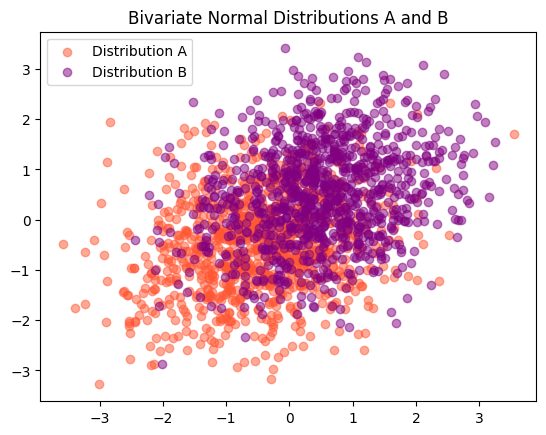

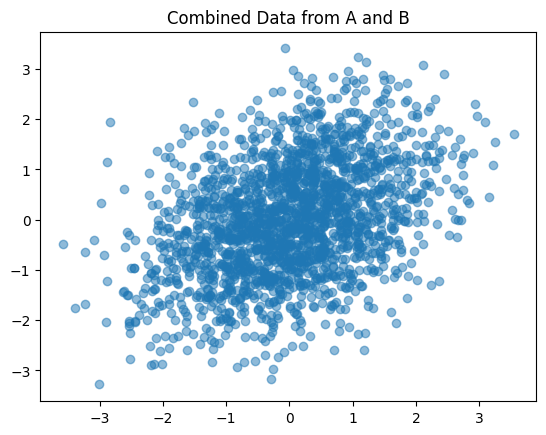

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


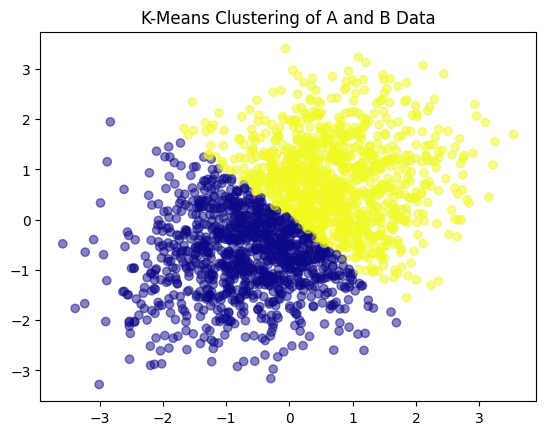

In [26]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans


mean_A = torch.tensor([-0.5, -0.5])
cov_A = torch.tensor([[1.0, 0.25], [0.25, 1.0]])

mean_B = torch.tensor([0.5, 0.5])
cov_B = torch.tensor([[1.0, 0.25], [0.25, 1.0]])


num_samples = 1000


dist_A = torch.distributions.MultivariateNormal(mean_A, cov_A)
dist_B = torch.distributions.MultivariateNormal(mean_B, cov_B)


data_A = dist_A.sample((num_samples,))
data_B = dist_B.sample((num_samples,))


combined_data = torch.cat([data_A, data_B], dim=0)


data_A_np = data_A.numpy()
data_B_np = data_B.numpy()

plt.scatter(data_A_np[:, 0], data_A_np[:, 1], color='#FF5733', label='Distribution A', alpha=0.5)
plt.scatter(data_B_np[:, 0], data_B_np[:, 1], color='purple', label='Distribution B', alpha=0.5)
plt.title("Bivariate Normal Distributions A and B")
plt.legend()
plt.show()


plt.scatter(combined_data[:, 0],  combined_data[:, 1], alpha=0.5)
plt.title("Combined Data from A and B")
plt.show()
combined_data_np = combined_data.numpy()

# Perform KMeans clustering
kmeans_model = KMeans(n_clusters=2)
kmeans_model.fit(combined_data_np)


cluster_labels = kmeans_model.labels_

plt.scatter(combined_data_np[:, 0], combined_data_np[:, 1], c=cluster_labels, cmap='plasma', alpha=0.5)
plt.title("K-Means Clustering of A and B Data")
plt.show()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


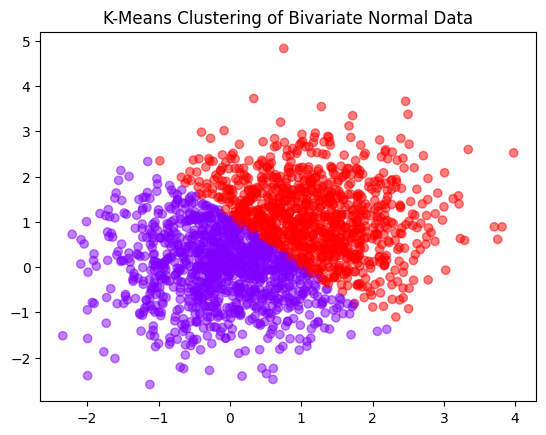

Cluster Centers:
 [[-0.14611572 -0.05782068]
 [ 1.1902351   1.1468835 ]]


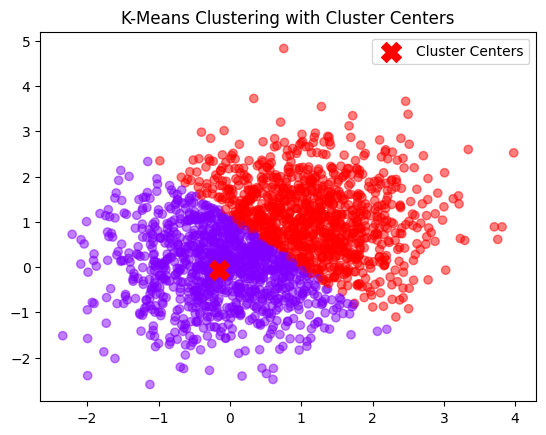

In [36]:
import torch
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


mean_C = torch.tensor([-0.5, -0.5])
cov_D = torch.tensor([[1.0, 0.25], [0.25, 1.0]])

mean_C = torch.tensor([0.5, 0.5])
cov_D = torch.tensor([[1.0, 0.25], [0.25, 1.0]])


num_samples = 1000

dis_A = torch.distributions.MultivariateNormal(mean_C, cov_D)
dis_B = torch.distributions.MultivariateNormal(mean_C, cov_D)

data_A = dis_A.sample((num_samples,))
data_B = dis_B.sample((num_samples,))


combined_data = torch.cat([data_A, data_B], dim=0)


combined_data_np = combined_data.numpy()


kmeans_model = KMeans(n_clusters=2, random_state=0)
kmeans_model.fit(combined_data_np)


cluster_labels = kmeans_model.labels_


plt.scatter(combined_data_np[:, 0], combined_data_np[:, 1], c=cluster_labels, cmap='rainbow', alpha=0.5)
plt.title("K-Means Clustering of Bivariate Normal Data")
plt.show()


cluster_centers = kmeans_model.cluster_centers_
print("Cluster Centers:\n", cluster_centers)


plt.scatter(combined_data_np[:, 0], combined_data_np[:, 1], c=cluster_labels, cmap='rainbow', alpha=0.5)
plt.scatter(cluster_centers[:, 0], cluster_centers[:, 1], c='red', marker='X', s=200, label='Cluster Centers')
plt.title("K-Means Clustering with Cluster Centers")
plt.legend()
plt.show()

In [10]:
from sklearn.decomposition import PCA
import torch
import matplotlib.pyplot as plt


mean_A = torch.tensor([-0.5, -0.5])
mean_B = torch.tensor([0.5, 0.5])

cov_A = torch.tensor([[1.0, 0.25], [0.25, 1.0]])
cov_B = torch.tensor([[1.0, 0.25], [0.25, 1.0]])

dist_A = torch.distributions.MultivariateNormal(mean_A, cov_A)
dist_B = torch.distributions.MultivariateNormal(mean_B, cov_B)


m = 1000
samples_A = dist_A.sample((m,))
samples_B = dist_B.sample((m,))

data = torch.cat((samples_A, samples_B), dim=0)



mean = torch.mean(data, dim=0)
std = torch.std(data, dim=0)
data_standardized = (data - mean) / std

cov_matrix = torch.mm(data_standardized.T, data_standardized) / data_standardized.shape[0]


eigenvalues_complex, eigenvectors_complex = torch.linalg.eig(cov_matrix)


eigenvalues = eigenvalues_complex.real
eigenvectors = eigenvectors_complex.real


eigenvalues_sorted, indices = torch.sort(eigenvalues, descending=True)
eigenvectors_sorted = eigenvectors[:, indices]
